# Decision Tree: Readable Rules for Customer Churn

**Family:** Supervised learning | **Level:** Intermediate | **Dataset:** `telco_churn` | **Runs on:** CPU, about 1 minute(s)

Grow a tree of if-then rules, then prune it so it generalises.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How a tree chooses splits with Gini impurity
- Why unpruned trees overfit
- How to read the rules of a small tree
- How to prune with depth limits and cost complexity

**Prerequisites:**

- Linear regression notebook
- Train, validation and test splits
- Confusion matrix basics

**Skills you will have afterwards:**

- Choose a hyperparameter on validation data
- Compare with a baseline
- Run a sensitivity experiment

## 2. Real-World Problem

**Context.** Subscription businesses lose revenue when customers leave, and winning a new customer costs more than keeping one.

**The problem.** Predict which telecom customers will churn from contract, billing and service information.

**Why it matters.** A ranked list of at risk customers lets a retention team spend a limited budget on the right people.

**Why machine learning.** Churn depends on many interacting attributes, and the history of past customers is available.

**Why this algorithm.** A shallow tree gives rules a retention manager can read and challenge.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Induction of decision trees

- **Type:** foundational paper
- **Authors:** Quinlan, J. R.
- **Year and venue:** 1986, Machine Learning 1(1):81-106
- **DOI or URL:** https://doi.org/10.1007/BF00116251
- **Verification:** Crossref 2026-11-17
- **Research objective:** Describe the ID3 method for building decision trees from examples.
- **Methodology:** Greedy top down splitting by information gain.
- **Dataset:** Chess endgame and other classification problems.
- **Main findings:** Compact trees can be induced from data with a simple entropy criterion.
- **Limitations:** Favours attributes with many values. Overfits without pruning.

### The Elements of Statistical Learning (2nd ed.)

- **Type:** foundational paper
- **Authors:** Hastie, T., Tibshirani, R. and Friedman, J.
- **Year and venue:** 2009, Springer
- **DOI or URL:** https://doi.org/10.1007/978-0-387-84858-7
- **Verification:** not verified in build environment
- **Research objective:** Textbook on statistical learning.
- **Methodology:** Textbook.
- **Dataset:** Not applicable.
- **Main findings:** Reference text.
- **Limitations:** Textbook.

**Relationship to this notebook.** Quinlan describes the ID3 family with information gain. scikit-learn implements CART style trees with Gini or entropy, so the principle is the same but the algorithm differs in details. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Impurity.** For class shares $p_k$ at a node, Gini is $G = \sum_k p_k(1-p_k)$ and entropy is $H = -\sum_k p_k \log_2 p_k$.

**Split choice.** For feature $j$ and threshold $t$, split rows into left $L$ and right $R$ and minimise

$$\frac{|L|}{|N|} G(L) + \frac{|R|}{|N|} G(R)$$

**Growth.** Recursive greedy splitting until a stopping rule (depth, minimum leaf size) or pure leaves.

**Cost complexity pruning.** Minimise $R(T) + \alpha |T|$ where $R(T)$ is the training error and $|T|$ the number of leaves.

**Assumptions.** None on the distribution.

**Limitations.** Greedy and unstable (small data changes give different trees), axis aligned splits only, high variance when deep.

## 5. Dataset Introduction

**Telco customer churn**, IBM sample data from the repository `IBM/telco-customer-churn-on-icp4d` (code licence Apache-2.0, dataset terms not stated). 7043 customers, 20 features: demographics (`gender`, `SeniorCitizen`, `Partner`, `Dependents`), account (`tenure` in months, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`) and services (`PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`). Target `Churn` (1 = customer left). `TotalCharges` has blank strings that become missing values. The file is downloaded once and checked against a SHA-256 hash. Limit: one snapshot, no time dimension. Duplicate rows are reported in the EDA but kept, because without an identifier we cannot tell whether they are different customers.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "decision_tree"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("telco_churn")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: classification | target: Churn | shape: (7043, 20)


,source
title,Telco customer churn
source,"IBM sample data, repository IBM/telco-customer..."
url,https://raw.githubusercontent.com/IBM/telco-cu...
license,"repository is Apache-2.0, dataset terms are no..."
doi,None
rows,7043
features,20
limits,One snapshot with no time dimension. The publi...


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. 

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (7043, 20)


,columns by dtype
str,15
int64,3
float64,2


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162,0.369,0.00,0.00,0.000,0.000,1.00
tenure,7043.0,32.371,24.559,0.00,9.00,29.000,55.000,72.00
MonthlyCharges,7043.0,64.762,30.090,18.25,35.50,70.350,89.850,118.75
TotalCharges,7032.0,2283.300,2266.771,18.80,401.45,1397.475,3794.738,8684.80
Churn,7043.0,0.265,0.442,0.00,0.00,0.000,1.000,1.00


Columns with missing values: 1


,missing,percent
TotalCharges,11,0.16


Duplicate rows: 22


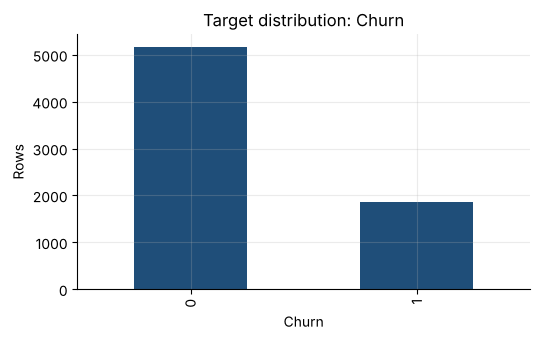

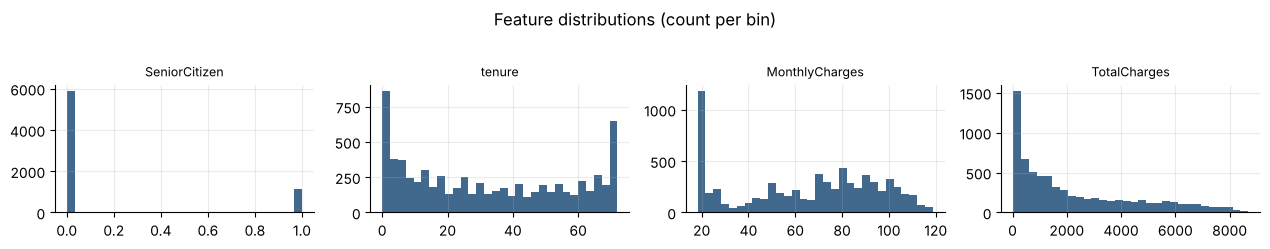

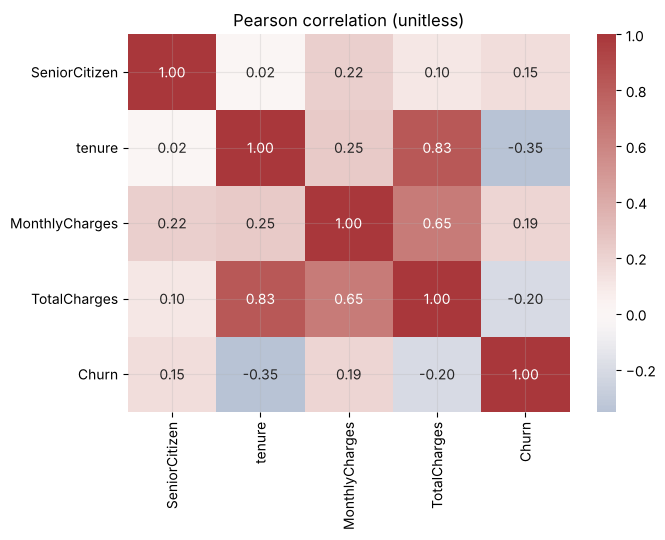

,feature,outliers,percent
0,SeniorCitizen,1142,16.21
1,tenure,0,0.00
2,MonthlyCharges,0,0.00
3,TotalCharges,0,0.00


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.

- `TotalCharges` is missing for new customers, so the median imputer is fitted on training rows only.
- Churn is the minority class, so we select models on PR-AUC (area under the precision recall curve) instead of accuracy.

In [5]:

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=False, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 4225 1409 1409


,train,validation,test
Churn,,,
0,0.735,0.735,0.735
1,0.265,0.265,0.265


transformed train shape: (4225, 45)


## 8. Algorithm Implementation

### 8.1 Concept

Each internal node asks one yes or no question about one feature, and each leaf stores the class share of the training rows that arrive there.

### 8.2 Python implementation from scratch

We grow a small tree with Gini impurity on quantile thresholds and compare it with scikit-learn at the same depth.

In [6]:
from sklearn.metrics import roc_auc_score
ytr = y_train.values
names = prep.get_feature_names_out()

def gini(y):
    p = y.mean()
    return 2 * p * (1 - p)

def best_split(X, y, min_leaf=30):
    best = (None, None, gini(y))
    for j in range(X.shape[1]):
        for t in np.unique(np.quantile(X[:, j], np.linspace(0.1, 0.9, 9))):
            left = X[:, j] <= t
            if left.sum() < min_leaf or (~left).sum() < min_leaf:
                continue
            impurity = (left.sum() * gini(y[left]) + (~left).sum() * gini(y[~left])) / len(y)
            if impurity < best[2]:
                best = (j, t, impurity)
    return best

def grow(X, y, depth):
    if depth == 0 or len(np.unique(y)) == 1:
        return ("leaf", y.mean())
    j, t, _ = best_split(X, y)
    if j is None:
        return ("leaf", y.mean())
    left = X[:, j] <= t
    return ("split", j, t, grow(X[left], y[left], depth - 1), grow(X[~left], y[~left], depth - 1))

def score_row(node, row):
    while node[0] == "split":
        node = node[3] if row[node[1]] <= node[2] else node[4]
    return node[1]

tree = grow(Xtr, ytr, depth=3)
print("root split on:", names[tree[1]], "<=", round(float(tree[2]), 3))
mine = np.array([score_row(tree, r) for r in Xva])
ref = DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, random_state=SEED).fit(Xtr, ytr)
print("validation ROC-AUC scratch:", round(roc_auc_score(y_val, mine), 3), "| sklearn:", round(roc_auc_score(y_val, ref.predict_proba(Xva)[:, 1]), 3))

root split on: cat__Contract_Month-to-month <= 0.0
validation ROC-AUC scratch: 0.809 | sklearn: 0.808


### 8.3 Library implementation

The estimator is wrapped in a pipeline so imputation, scaling and encoding are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `max_depth` | Longest root to leaf path. |
| `min_samples_leaf` | Smallest allowed leaf. |
| `criterion` | `gini` or `entropy`. |
| `ccp_alpha` | Cost complexity pruning strength. |

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [7]:
SELECT = "PR_AUC"
LOWER_IS_BETTER = False
SCORING = "average_precision"
SWEEP_PARAM = "model__max_depth"
SWEEP_VALUES = [1, 2, 3, 4, 5, 6, 8, 12]

def build_pipeline():
    return make_model_pipeline(X_train, DecisionTreeClassifier(min_samples_leaf=20, random_state=SEED), scale=False, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

DecisionTreeClassifier(min_samples_leaf=20, random_state=42)


,PR_AUC,Accuracy,F1,ROC_AUC,PR_AUC
model__max_depth,,,,,
1,0.3972,0.7346,0.0000,0.7148,0.3972
2,0.4813,0.7587,0.5792,0.7798,0.4813
3,0.5603,0.7906,0.4797,0.8083,0.5603
4,0.5993,0.7949,0.5405,0.8225,0.5993
5,0.5957,0.7850,0.5136,0.8236,0.5957
6,0.5783,0.7764,0.4861,0.8174,0.5783
8,0.6018,0.7857,0.5266,0.8177,0.6018
12,0.6039,0.7885,0.5415,0.8111,0.6039


best model__max_depth on validation: 12
refit on train plus validation rows


## 10. Evaluation

Classification metrics: accuracy, precision, recall, F1, ROC-AUC and PR-AUC, plus the confusion matrix. With imbalanced classes accuracy alone misleads, so the model is chosen on F1 or PR-AUC as stated in the training cell.

A dummy model gives the floor every real model must beat.

In [8]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "DecisionTreeClassifier": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="DecisionTreeClassifier", dataset="telco_churn",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
baseline,0.7346,0.000,0.0000,0.0000,0.5000,0.2654
DecisionTreeClassifier,0.7871,0.625,0.4947,0.5522,0.8158,0.6057


5-fold CV average_precision: mean 0.5996, std 0.0266
saved decision_tree.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

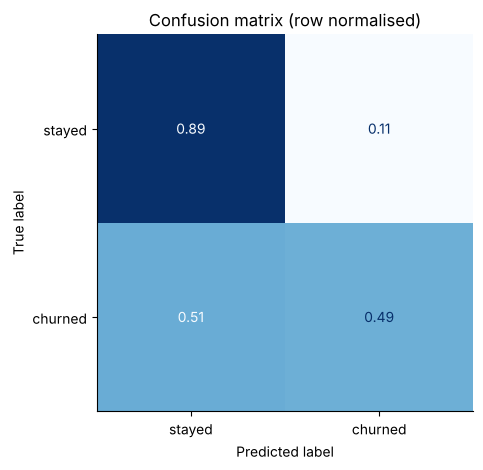

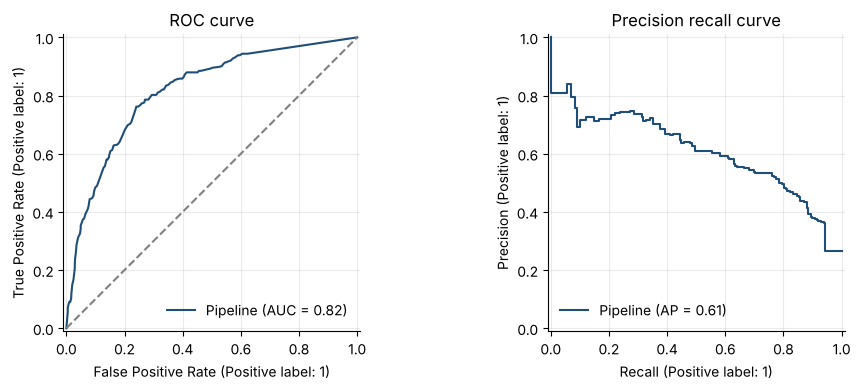

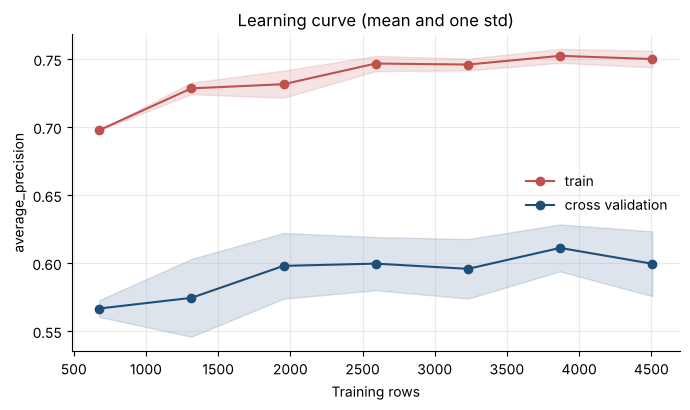

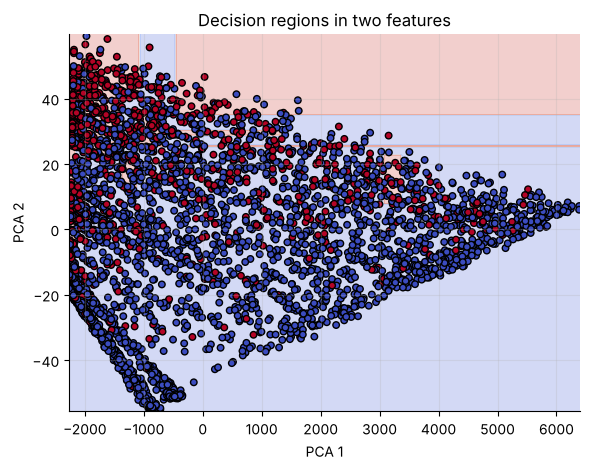

In [9]:
pred = final_model.predict(X_test)
labels = bundle.target_names or None
fig = viz.plot_confusion(y_test, pred, labels=labels)
save_figure(fig, NOTEBOOK_ID, "confusion"); plt.show()
if y_test.nunique() == 2:
    fig = viz.plot_roc_pr(final_model, X_test, y_test)
    save_figure(fig, NOTEBOOK_ID, "roc_pr"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()
# decision regions in two PCA axes
pca_view = PCA(n_components=2, random_state=SEED).fit(Xtr)
model_for_plot = clone(final_model.named_steps["model"])
fig = viz.plot_decision_boundary(lambda: clone(model_for_plot), pca_view.transform(Xtr), y_train.values,
                                 names=["PCA 1", "PCA 2"])
save_figure(fig, NOTEBOOK_ID, "decision_regions"); plt.show()

## 12. Interpretation

Permutation importance shows which inputs the model relies on. The confusion matrix shows which classes are mixed up, and the list of misclassified rows is the starting point for error analysis. A model is only as good as the cases it fails on.

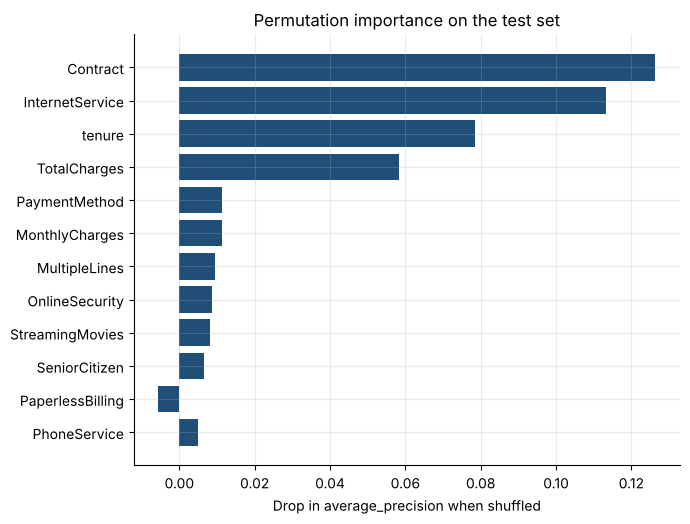

Top features: Contract, InternetService, tenure, TotalCharges, PaymentMethod
Misclassified test rows: 300 of 1409

Test PR_AUC: 0.6057 | baseline PR_AUC: 0.2654
Cross validation spread (std): 0.0266. A test gap larger than this spread is meaningful.


In [10]:
perm = permutation_importance(final_model, X_test, y_test, scoring=SCORING, n_repeats=10, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig = viz.plot_importance(importance.index, importance.values, title="Permutation importance on the test set",
                          top=12, xlabel="Drop in " + SCORING + " when shuffled")
save_figure(fig, NOTEBOOK_ID, "importance"); plt.show()
print("Top features:", ", ".join(importance.index[:5]))
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

## 13. Experiments and Challenges

### Experiment 1: Read the rules

Print the text rules of a depth 3 tree.

In [11]:
small = make_model_pipeline(X_train, DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=SEED), scale=False).fit(X_train, y_train)
print(export_text(small.named_steps["model"], feature_names=list(small.named_steps["prep"].get_feature_names_out()), max_depth=3))

|--- cat__Contract_Month-to-month <= 0.50
|   |--- num__MonthlyCharges <= 93.78
|   |   |--- cat__OnlineSecurity_No <= 0.50
|   |   |   |--- class: 0
|   |   |--- cat__OnlineSecurity_No >  0.50
|   |   |   |--- class: 0
|   |--- num__MonthlyCharges >  93.78
|   |   |--- num__TotalCharges <= 6623.50
|   |   |   |--- class: 0
|   |   |--- num__TotalCharges >  6623.50
|   |   |   |--- class: 0
|--- cat__Contract_Month-to-month >  0.50
|   |--- cat__InternetService_Fiber optic <= 0.50
|   |   |--- num__tenure <= 3.50
|   |   |   |--- class: 0
|   |   |--- num__tenure >  3.50
|   |   |   |--- class: 0
|   |--- cat__InternetService_Fiber optic >  0.50
|   |   |--- num__tenure <= 15.50
|   |   |   |--- class: 1
|   |   |--- num__tenure >  15.50
|   |   |   |--- class: 0



### Experiment 2: Cost complexity pruning

Grow a deep tree and prune it. Cross validated PR-AUC is computed for several alphas.

In [12]:
from sklearn.model_selection import cross_val_score
for alpha in [0.0, 0.0005, 0.002, 0.005, 0.01]:
    s = cross_val_score(make_model_pipeline(X_trainval, DecisionTreeClassifier(ccp_alpha=alpha, random_state=SEED), scale=False), X_trainval, y_trainval, cv=5, scoring="average_precision")
    print(f"ccp_alpha={alpha}: CV PR-AUC {s.mean():.3f} +- {s.std(ddof=1):.3f}")

ccp_alpha=0.0: CV PR-AUC 0.379 +- 0.011


ccp_alpha=0.0005: CV PR-AUC 0.570 +- 0.018


ccp_alpha=0.002: CV PR-AUC 0.577 +- 0.011


ccp_alpha=0.005: CV PR-AUC 0.553 +- 0.012


ccp_alpha=0.01: CV PR-AUC 0.539 +- 0.011


### Experiment 3: Class weights for the minority class

Balanced class weights raise recall at the cost of precision.

In [13]:
from sklearn.metrics import precision_score, recall_score
for cw in [None, "balanced"]:
    m = make_model_pipeline(X_train, DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight=cw, random_state=SEED), scale=False).fit(X_train, y_train)
    p = m.predict(X_val)
    print(f"class_weight={cw}: precision {precision_score(y_val, p):.3f}, recall {recall_score(y_val, p):.3f}")

class_weight=None: precision 0.643, recall 0.428
class_weight=balanced: precision 0.493, recall 0.799


### Exercises for learners

1. Repeat the notebook with `SEED = 7` and report how much the headline metric changes.
2. Change the metric used for model choice and see whether the chosen value changes.
3. Replace the validation sweep with `GridSearchCV` and compare the chosen value.

## 14. Research Discussion

Quinlan presents trees as compact rule sets learned from examples. Our printed rules show the same readability on churn data. We did not use information gain exactly as in ID3.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Use ensembles (random forest, boosting) for accuracy and keep a shallow tree as an explanation surrogate.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- Trees give readable rules.
- Depth and leaf size control overfitting.
- Single trees are unstable.

**Use cases.** Rule based decisions, explanation, base learner for ensembles.

**Limitations.** High variance and axis aligned splits.

**Recommended next notebook.** Random Forest.

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.